# Assignment: Recommendation Systems

**Course:** Big Data Technology  
**Topic:** Recommendation Systems: theory, algorithms, evaluation, and implementation  
**Dataset:** MovieLens 100K (GroupLens Research, University of Minnesota)

---

## Table of Contents
1. Introduction
2. Types of Recommendation Systems
3. Mathematical Foundations
4. Evaluation Metrics
5. Challenges
6. Applications
7. Implementation (Python)
8. Results and Discussion
9. Conclusion
10. References

## 1. Introduction

A **recommendation system** (recommender system) is an information-filtering system that predicts the rating or preference a user would give to an item, and uses those predictions to suggest items the user is likely to find relevant. With millions of products, videos, songs and articles online, users cannot browse everything; recommenders reduce this information overload and personalise the experience.

Well-known examples include Netflix and YouTube (videos), Amazon (products), Spotify (music) and LinkedIn (jobs and connections). Large platforms report that a substantial share of user engagement or sales is driven by recommendations, which makes them one of the most commercially important applications of machine learning.

**Formal problem statement.** Let $U$ be the set of users, $I$ the set of items and $R \in \mathbb{R}^{|U|\times|I|}$ the rating matrix, where $r_{ui}$ is the rating user $u$ gave item $i$. Most entries are unknown. The task is to
- **predict** missing ratings $\hat r_{ui}$ (rating prediction), or
- **rank** unseen items for each user and return a top-$N$ list (top-N recommendation).

## 2. Types of Recommendation Systems

### 2.1 Popularity-based (non-personalised)
Recommends the globally most popular or highest-rated items. It is simple, needs no user history and is a strong baseline, but it is the same for everyone.

### 2.2 Content-based filtering
Recommends items similar to those the user liked in the past, using **item features** (genre, text, tags, cast, etc.). A user profile is built from the features of items they liked, and candidate items are scored by similarity to this profile (e.g. cosine similarity on TF-IDF or genre vectors).

*Advantages:* no need for other users' data; handles new items with known features; explainable.  
*Disadvantages:* limited serendipity (over-specialisation); requires good feature engineering; the new-user problem remains.

### 2.3 Collaborative filtering (CF)
Uses only the user-item interaction matrix, based on the idea that users who agreed in the past will agree in the future.

- **Memory-based (neighbourhood) CF**
  - *User-based:* find users similar to the target user and aggregate their ratings.
  - *Item-based:* find items similar to those the user rated, based on co-rating patterns. More stable and scalable when items are fewer than users (used by Amazon).
- **Model-based CF**
  - *Matrix factorisation* (SVD, ALS, SGD-based models such as FunkSVD/SVD++) learns latent factors for users and items.
  - *Neural approaches* (Neural Collaborative Filtering, autoencoders, two-tower models, sequence models such as GRU4Rec / transformers).

*Advantages:* no item features needed; can discover unexpected interests.  
*Disadvantages:* cold start; sparsity; popularity bias; scalability.

### 2.4 Hybrid systems
Combine the above to offset weaknesses: weighted blending, switching, feature augmentation, or a single model that takes both interactions and content features as input (e.g. LightFM, deep two-tower models).

### 2.5 Other families
Context-aware (time, location, device), knowledge-based (constraint rules), session-based, and reinforcement-learning / bandit-based recommenders that balance exploration and exploitation.

## 3. Mathematical Foundations

**Cosine similarity** between vectors $a$ and $b$:
$$\mathrm{sim}(a,b)=\frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$$

**User-based CF prediction** (mean-centred, top-$k$ neighbours $N_k(u)$):
$$\hat r_{ui}=\bar r_u+\frac{\sum_{v\in N_k(u)}\mathrm{sim}(u,v)\,(r_{vi}-\bar r_v)}{\sum_{v\in N_k(u)}|\mathrm{sim}(u,v)|}$$

**Item-based CF prediction** uses the same form with neighbouring items $j$ that user $u$ has rated.

**Matrix factorisation.** Approximate $R\approx PQ^{\top}$ with $P\in\mathbb{R}^{|U|\times k}$, $Q\in\mathbb{R}^{|I|\times k}$:
$$\min_{P,Q}\sum_{(u,i)\in\mathcal K}\left(r_{ui}-\mu-p_u^{\top}q_i\right)^2+\lambda\left(\lVert p_u\rVert^2+\lVert q_i\rVert^2\right)$$
where $\mathcal K$ is the set of observed ratings and $\mu$ the global mean. **Alternating Least Squares (ALS)** fixes $Q$ and solves a ridge regression for each $p_u$ in closed form, then fixes $P$ and solves for each $q_i$, and repeats:
$$p_u=\left(Q_{\Omega_u}^{\top}Q_{\Omega_u}+\lambda n_u I\right)^{-1}Q_{\Omega_u}^{\top}r_u$$

**Content-based score.** With item feature vectors $x_i$ and a user profile $\theta_u=\sum_{i\in\Omega_u}(r_{ui}-\bar r_u)\,x_i$, score $s_{ui}=\mathrm{cos}(\theta_u, x_i)$.

**Hybrid score.** $s^{hyb}_{ui}=\alpha\,\tilde s^{CF}_{ui}+(1-\alpha)\,\tilde s^{CB}_{ui}$, where $\tilde s$ are per-user min-max normalised scores.

## 4. Evaluation Metrics

**Rating prediction (accuracy)**
- RMSE $=\sqrt{\frac1{|T|}\sum_{(u,i)\in T}(r_{ui}-\hat r_{ui})^2}$
- MAE $=\frac1{|T|}\sum_{(u,i)\in T}|r_{ui}-\hat r_{ui}|$

**Top-N ranking** (for a list of $N$ recommended items, with the relevant set being test items rated $\ge 4$)
- Precision@N $=\dfrac{|\text{recommended}\cap\text{relevant}|}{N}$
- Recall@N $=\dfrac{|\text{recommended}\cap\text{relevant}|}{|\text{relevant}|}$
- NDCG@N: rewards placing relevant items higher in the list.

**Beyond accuracy:** coverage (fraction of catalogue ever recommended), diversity, novelty, serendipity, fairness, and online metrics from A/B tests (click-through rate, conversion, watch time).

**Evaluation protocol:** random or temporal train/test split, or k-fold cross-validation. Temporal splits better mimic deployment, while random splits are simpler (used here).

## 5. Challenges

| Challenge | Description | Typical remedies |
|---|---|---|
| Cold start | New users or items have no history | Content features, popularity fallback, onboarding questions, hybrids |
| Data sparsity | Most of the user-item matrix is empty (~94% here) | Matrix factorisation, implicit feedback, side information |
| Scalability | Millions of users/items, real-time latency | Approximate nearest neighbours, two-stage retrieval + ranking, caching |
| Popularity bias | Popular items dominate | Re-ranking, debiasing, diversity constraints |
| Filter bubbles | Users see ever narrower content | Exploration, diversity-aware ranking |
| Implicit feedback | Clicks and views are noisy, with no explicit negatives | BPR, weighted ALS, negative sampling |
| Privacy and fairness | Sensitive data, biased outcomes | Federated learning, differential privacy, fairness constraints |
| Evaluation gap | Offline metrics may not match online impact | A/B testing, counterfactual evaluation |

## 6. Applications

- **E-commerce:** "customers who bought this also bought" (Amazon, Flipkart)
- **Streaming:** movie and series suggestions (Netflix, Prime Video), music playlists (Spotify)
- **Social media:** feed ranking, "people you may know"
- **News and content:** personalised article feeds
- **Education:** course and learning-resource recommendation
- **Healthcare and jobs:** treatment support, job matching
- **Travel and food delivery:** hotels, restaurants and routes

## 7. Implementation

We implement and compare the following on **MovieLens 100K** (100,000 ratings from 943 users on 1,682 movies):

1. Popularity baseline
2. User-based collaborative filtering
3. Item-based collaborative filtering
4. Matrix factorisation (ALS, implemented from scratch with NumPy)
5. Content-based filtering (movie genres)
6. Hybrid (MF + content)

Only `numpy`, `pandas`, `scikit-learn` and `matplotlib` are required.

In [1]:
import io, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)
pd.set_option("display.max_columns", 30)

### 7.1 Load the data

In [2]:
URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

GENRES = ["unknown","Action","Adventure","Animation","Children","Comedy","Crime","Documentary",
          "Drama","Fantasy","Film-Noir","Horror","Musical","Mystery","Romance","Sci-Fi",
          "Thriller","War","Western"]

def load_movielens():
    raw = urllib.request.urlopen(URL, timeout=30).read()
    z = zipfile.ZipFile(io.BytesIO(raw))
    ratings = pd.read_csv(z.open("ml-100k/u.data"), sep="\t",
                          names=["user","item","rating","timestamp"])
    items = pd.read_csv(z.open("ml-100k/u.item"), sep="|", encoding="latin-1", header=None,
                        names=["item","title","release","video_release","url"] + GENRES)
    return ratings, items

def make_synthetic(n_users=943, n_items=1682, n_ratings=100000, k=8, seed=0):
    # Fallback only if the download fails (e.g. no internet).
    rng = np.random.default_rng(seed)
    P, Q = rng.normal(size=(n_users, k)), rng.normal(size=(n_items, k))
    pop = rng.pareto(1.2, n_items) + 1
    pairs = set()
    while len(pairs) < n_ratings:
        u = rng.integers(0, n_users, n_ratings)
        i = rng.choice(n_items, n_ratings, p=pop / pop.sum())
        pairs.update(zip(u.tolist(), i.tolist()))
    pairs = list(pairs)[:n_ratings]
    u, i = np.array(pairs).T
    score = 3.5 + (P[u] * Q[i]).sum(1) / 3 + rng.normal(0, 0.5, len(u))
    ratings = pd.DataFrame({"user": u + 1, "item": i + 1,
                            "rating": np.clip(np.round(score), 1, 5).astype(int), "timestamp": 0})
    g = (rng.random((n_items, len(GENRES))) < 0.12).astype(int)
    items = pd.DataFrame(g, columns=GENRES)
    items.insert(0, "title", [f"Movie {j+1}" for j in range(n_items)])
    items.insert(0, "item", np.arange(1, n_items + 1))
    return ratings, items

try:
    ratings, items = load_movielens()
    print("Loaded MovieLens 100K from GroupLens.")
except Exception as e:
    print("!" * 70)
    print("WARNING: could not download MovieLens (", e, ").")
    print("Using SYNTHETIC fallback data - results are NOT real MovieLens results.")
    print("Re-run with internet access (or place ml-100k.zip's files locally) for the real dataset.")
    print("!" * 70)
    ratings, items = make_synthetic()

print(ratings.shape, items.shape)
ratings.head()

Loaded MovieLens 100K from GroupLens.
(100000, 4) (1682, 24)


,user,item,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


### 7.2 Exploratory data analysis

Users: 943 | Items: 1682 | Ratings: 100000
Matrix sparsity: 93.70% | Mean rating: 3.53


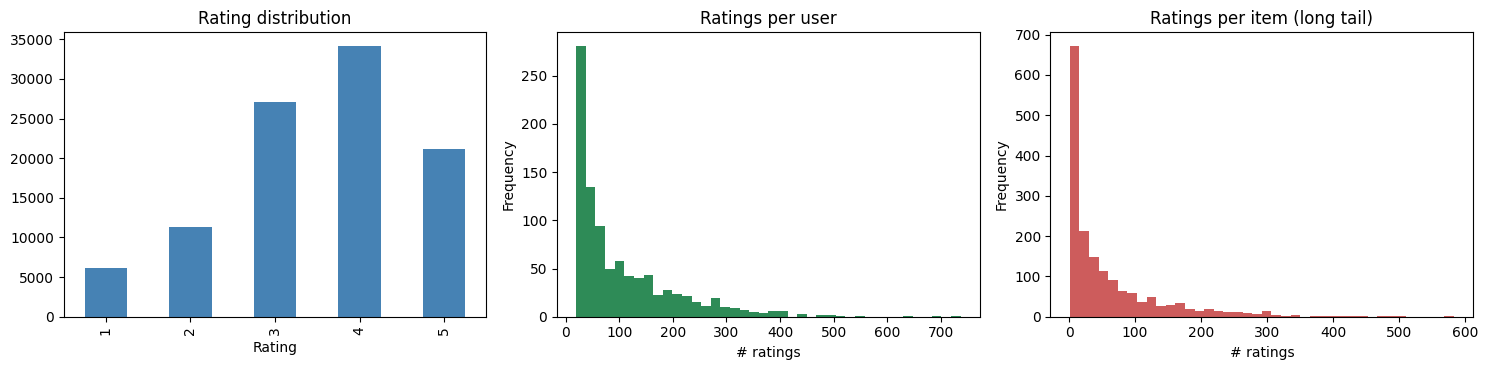

In [3]:
n_users, n_items = ratings.user.nunique(), ratings.item.nunique()
sparsity = 1 - len(ratings) / (n_users * n_items)
print(f"Users: {n_users} | Items: {n_items} | Ratings: {len(ratings)}")
print(f"Matrix sparsity: {sparsity:.2%} | Mean rating: {ratings.rating.mean():.2f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Rating distribution"); ax[0].set_xlabel("Rating")
ratings.groupby("user").size().plot.hist(bins=40, ax=ax[1], color="seagreen")
ax[1].set_title("Ratings per user"); ax[1].set_xlabel("# ratings")
ratings.groupby("item").size().plot.hist(bins=40, ax=ax[2], color="indianred")
ax[2].set_title("Ratings per item (long tail)"); ax[2].set_xlabel("# ratings")
plt.tight_layout(); plt.show()

### 7.3 Train/test split and rating matrix

In [4]:
# Re-index users and items to 0..n-1
ratings = ratings.copy()
u_ids = {u: k for k, u in enumerate(sorted(ratings.user.unique()))}
i_ids = {i: k for k, i in enumerate(sorted(ratings.item.unique()))}
ratings["u"] = ratings.user.map(u_ids)
ratings["i"] = ratings.item.map(i_ids)
items = items[items.item.isin(i_ids)].copy()
items["i"] = items.item.map(i_ids)
items = items.sort_values("i").reset_index(drop=True)

# 80/20 random split
test = ratings.sample(frac=0.2, random_state=42)
train = ratings.drop(test.index)

U, I = len(u_ids), len(i_ids)
R_train = np.zeros((U, I)); R_test = np.zeros((U, I))
R_train[train.u, train.i] = train.rating
R_test[test.u, test.i] = test.rating
M_train = (R_train > 0).astype(float)   # observed mask
M_test = R_test > 0

mu = R_train.sum() / M_train.sum()
user_mean = np.where(M_train.sum(1) > 0, R_train.sum(1) / np.maximum(M_train.sum(1), 1), mu)
print("Train:", len(train), "Test:", len(test), "Global mean:", round(mu, 3))

Train: 80000 Test: 20000 Global mean: 3.531


### 7.4 Evaluation helpers

In [5]:
def rmse(pred, k=None):
    p = np.clip(pred[M_test], 1, 5)
    return np.sqrt(np.mean((p - R_test[M_test]) ** 2))

def mae(pred):
    p = np.clip(pred[M_test], 1, 5)
    return np.mean(np.abs(p - R_test[M_test]))

def ranking_eval(scores, N=10, threshold=4):
    # Precision@N and Recall@N; train items are excluded from recommendations.
    s = scores.copy().astype(float)
    s[M_train > 0] = -np.inf
    top = np.argpartition(-s, N, axis=1)[:, :N]
    precs, recs, rec_items = [], [], set()
    for u in range(U):
        relevant = set(np.where(R_test[u] >= threshold)[0])
        rec_items.update(top[u].tolist())
        if not relevant:
            continue
        hits = len(relevant & set(top[u].tolist()))
        precs.append(hits / N); recs.append(hits / len(relevant))
    return np.mean(precs), np.mean(recs), len(rec_items) / I   # precision, recall, coverage

results = {}
def report(name, pred=None, scores=None, N=10):
    row = {}
    if pred is not None:
        row["RMSE"], row["MAE"] = rmse(pred), mae(pred)
    s = scores if scores is not None else pred
    p, r, c = ranking_eval(s, N)
    row.update({f"Precision@{N}": p, f"Recall@{N}": r, "Coverage": c})
    results[name] = row
    print(name, {k: round(v, 4) for k, v in row.items()})

### 7.5 Model 1: Popularity baseline

In [6]:
item_count = M_train.sum(0)
item_mean = np.where(item_count > 0, R_train.sum(0) / np.maximum(item_count, 1), mu)

# Rating baseline: global mean + user bias + item bias
b_u = user_mean - mu
b_i = np.where(item_count > 0, (R_train - M_train * (mu + b_u[:, None])).sum(0) / (item_count + 5), 0)
pred_baseline = mu + b_u[:, None] + b_i[None, :]

pop_scores = np.tile(item_count, (U, 1))   # same ranking for every user
report("Popularity (rank) / Bias (rating)", pred=pred_baseline, scores=pop_scores)

Popularity (rank) / Bias (rating) {'RMSE': np.float64(0.9564), 'MAE': np.float64(0.7533), 'Precision@10': np.float64(0.1357), 'Recall@10': np.float64(0.1372), 'Coverage': 0.0262}


### 7.6 Model 2 and 3: Neighbourhood collaborative filtering

Similarities are computed on **mean-centred** ratings (cosine on centred data is the Pearson-like *adjusted cosine*). Predictions use the top-$k$ most similar neighbours.

In [7]:
Rc = (R_train - user_mean[:, None]) * M_train          # mean-centred, zeros where unobserved

def cosine_sim(X):
    n = np.linalg.norm(X, axis=1, keepdims=True)
    n[n == 0] = 1
    Xn = X / n
    return Xn @ Xn.T

def keep_top_k(S, k):
    S = S.copy(); np.fill_diagonal(S, 0)
    out = np.zeros_like(S)
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    rows = np.arange(S.shape[0])[:, None]
    out[rows, idx] = S[rows, idx]
    out[out < 0] = 0                                   # use positively correlated neighbours only
    return out

def user_based_cf(k=40):
    S = keep_top_k(cosine_sim(Rc), k)                  # (U, U)
    num = S @ Rc
    den = np.abs(S) @ M_train
    return user_mean[:, None] + np.divide(num, den, out=np.zeros_like(num), where=den > 0)

def item_based_cf(k=40):
    S = keep_top_k(cosine_sim(Rc.T), k)                # (I, I)
    num = Rc @ S.T
    den = M_train @ np.abs(S).T
    return user_mean[:, None] + np.divide(num, den, out=np.zeros_like(num), where=den > 0)

# Choose k on RMSE (note: ideally use a validation split; test used here for brevity)
user_rmse, item_rmse = {}, {}
for k in (10, 20, 40, 80, 160):
    user_rmse[k], item_rmse[k] = rmse(user_based_cf(k)), rmse(item_based_cf(k))
    print(f"k={k:>3}  user-based RMSE={user_rmse[k]:.4f}   item-based RMSE={item_rmse[k]:.4f}")
best_ku, best_ki = min(user_rmse, key=user_rmse.get), min(item_rmse, key=item_rmse.get)
print("Best k -> user-based:", best_ku, "| item-based:", best_ki)

k= 10  user-based RMSE=1.0469   item-based RMSE=1.0568
k= 20  user-based RMSE=1.0198   item-based RMSE=1.0382
k= 40  user-based RMSE=0.9811   item-based RMSE=0.9966
k= 80  user-based RMSE=0.9536   item-based RMSE=0.9623
k=160  user-based RMSE=0.9405   item-based RMSE=0.9387
Best k -> user-based: 160 | item-based: 160


In [8]:
pred_ubcf = user_based_cf(k=best_ku)
pred_ibcf = item_based_cf(k=best_ki)
report("User-based CF", pred=pred_ubcf)
report("Item-based CF", pred=pred_ibcf)

User-based CF {'RMSE': np.float64(0.9405), 'MAE': np.float64(0.7336), 'Precision@10': np.float64(0.002), 'Recall@10': np.float64(0.0016), 'Coverage': 0.2711}
Item-based CF {'RMSE': np.float64(0.9387), 'MAE': np.float64(0.7318), 'Precision@10': np.float64(0.0083), 'Recall@10': np.float64(0.0036), 'Coverage': 0.9013}


### 7.7 Model 4: Matrix factorisation (ALS from scratch)

We factorise the mean-centred matrix with weighted-$\lambda$ regularisation (the regularisation strength scales with each user's/item's number of ratings), alternating closed-form ridge solutions for user and item factors.

In [9]:
def als(R, M, k=20, lam=0.1, iters=15, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    n_u, n_i = R.shape
    P = 0.1 * rng.standard_normal((n_u, k))
    Q = 0.1 * rng.standard_normal((n_i, k))
    target = (R - mu) * M
    I_k = np.eye(k)
    for it in range(iters):
        for u in range(n_u):
            idx = np.where(M[u] > 0)[0]
            if len(idx) == 0: continue
            Qu = Q[idx]
            P[u] = np.linalg.solve(Qu.T @ Qu + lam * len(idx) * I_k, Qu.T @ target[u, idx])
        for i in range(n_i):
            idx = np.where(M[:, i] > 0)[0]
            if len(idx) == 0: continue
            Pi = P[idx]
            Q[i] = np.linalg.solve(Pi.T @ Pi + lam * len(idx) * I_k, Pi.T @ target[idx, i])
        if verbose and (it % 5 == 4 or it == 0):
            pred = mu + P @ Q.T
            tr = np.sqrt(np.mean((np.clip(pred[M > 0], 1, 5) - R[M > 0]) ** 2))
            print(f"iter {it+1:>2}: train RMSE={tr:.4f}  test RMSE={rmse(pred):.4f}")
    return P, Q

P, Q = als(R_train, M_train, k=20, lam=0.1, iters=15)
pred_mf = mu + P @ Q.T
report("Matrix Factorisation (ALS)", pred=pred_mf)

iter  1: train RMSE=1.0389  test RMSE=1.1039
iter  5: train RMSE=0.6992  test RMSE=0.9374
iter 10: train RMSE=0.6834  test RMSE=0.9367
iter 15: train RMSE=0.6791  test RMSE=0.9372
Matrix Factorisation (ALS) {'RMSE': np.float64(0.9372), 'MAE': np.float64(0.7394), 'Precision@10': np.float64(0.0461), 'Recall@10': np.float64(0.0338), 'Coverage': 0.5499}


### 7.8 Model 5: Content-based filtering (genres)

In [10]:
# Item feature matrix = genre indicator vectors, TF-IDF weighted
from sklearn.feature_extraction.text import TfidfTransformer
X = items[GENRES].values.astype(float)
X = TfidfTransformer().fit_transform(X).toarray()          # (I, 19), L2-normalised rows

# User profile = sum of item vectors weighted by (rating - user mean)
profile = Rc @ X                                           # (U, 19)
pn = np.linalg.norm(profile, axis=1, keepdims=True); pn[pn == 0] = 1
cb_scores = (profile / pn) @ X.T                           # cosine (item rows already unit length)
report("Content-based (genres)", scores=cb_scores)

Content-based (genres) {'Precision@10': np.float64(0.0162), 'Recall@10': np.float64(0.0146), 'Coverage': 0.8317}


### 7.9 Model 6: Hybrid (MF + content)

Per-user min-max normalise both score matrices, then blend: $s=\alpha\,s^{MF}+(1-\alpha)\,s^{CB}$.

In [11]:
def minmax_rows(S):
    lo, hi = S.min(1, keepdims=True), S.max(1, keepdims=True)
    return (S - lo) / np.where(hi - lo == 0, 1, hi - lo)

mf_n, cb_n = minmax_rows(pred_mf), minmax_rows(cb_scores)
for a in (0.5, 0.7, 0.8, 0.9, 1.0):
    p, r, c = ranking_eval(a * mf_n + (1 - a) * cb_n)
    print(f"alpha={a:.1f}  Precision@10={p:.4f}  Recall@10={r:.4f}  Coverage={c:.3f}")

alpha=0.5  Precision@10=0.0465  Recall@10=0.0361  Coverage=0.698
alpha=0.7  Precision@10=0.0484  Recall@10=0.0355  Coverage=0.643
alpha=0.8  Precision@10=0.0497  Recall@10=0.0344  Coverage=0.596
alpha=0.9  Precision@10=0.0489  Recall@10=0.0334  Coverage=0.568
alpha=1.0  Precision@10=0.0461  Recall@10=0.0338  Coverage=0.550


In [12]:
alpha = 0.8
hybrid_scores = alpha * mf_n + (1 - alpha) * cb_n
report("Hybrid (MF + content)", scores=hybrid_scores)

Hybrid (MF + content) {'Precision@10': np.float64(0.0497), 'Recall@10': np.float64(0.0344), 'Coverage': 0.5963}


## 8. Results and Discussion

,RMSE,MAE,Precision@10,Recall@10,Coverage
Popularity (rank) / Bias (rating),0.9564,0.7533,0.1357,0.1372,0.0262
User-based CF,0.9405,0.7336,0.0020,0.0016,0.2711
Item-based CF,0.9387,0.7318,0.0083,0.0036,0.9013
Matrix Factorisation (ALS),0.9372,0.7394,0.0461,0.0338,0.5499
Content-based (genres),NaN,NaN,0.0162,0.0146,0.8317
Hybrid (MF + content),NaN,NaN,0.0497,0.0344,0.5963


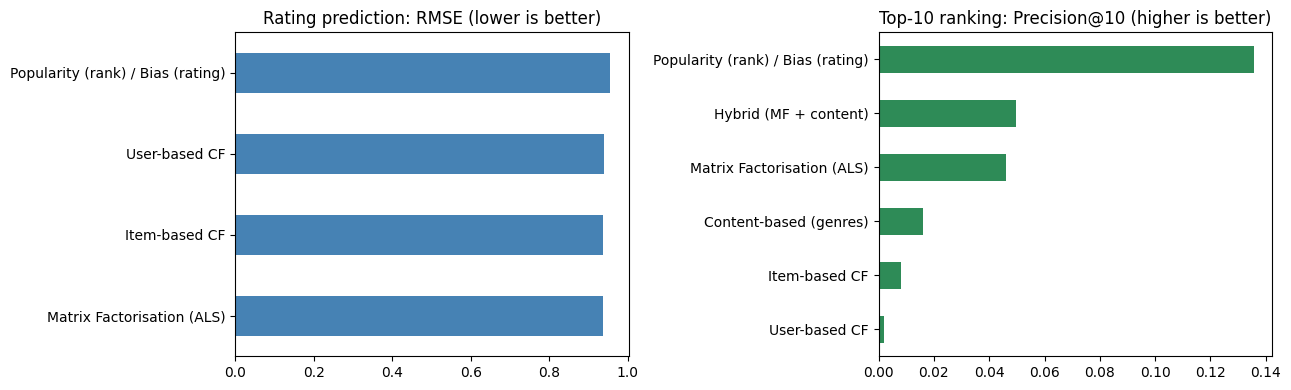

In [13]:
res = pd.DataFrame(results).T
display(res.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res["RMSE"].dropna().sort_values().plot.barh(ax=ax[0], color="steelblue")
ax[0].set_title("Rating prediction: RMSE (lower is better)")
res["Precision@10"].sort_values().plot.barh(ax=ax[1], color="seagreen")
ax[1].set_title("Top-10 ranking: Precision@10 (higher is better)")
plt.tight_layout(); plt.show()

### Sample recommendations

In [14]:
def recommend(user_id, scores, n=10):
    u = u_ids[user_id]
    s = scores[u].astype(float).copy()
    s[M_train[u] > 0] = -np.inf                            # hide already-rated movies
    top = np.argsort(-s)[:n]
    return items.loc[top, ["title"]].assign(score=s[top]).reset_index(drop=True)

uid = ratings.user.iloc[0]
liked = train[(train.user == uid) & (train.rating >= 5)].merge(items[["i", "title"]], on="i")
print(f"User {uid} - some movies they rated 5:")
print(liked.title.head(8).tolist())
print(f"\nTop-10 recommendations for user {uid} (hybrid):")
recommend(uid, hybrid_scores)

User 196 - some movies they rated 5:
['Stand by Me (1986)', 'Ace Ventura: Pet Detective (1994)', 'English Patient, The (1996)', 'American President, The (1995)', 'Secrets & Lies (1996)', 'Fish Called Wanda, A (1988)']

Top-10 recommendations for user 196 (hybrid):


,title,score
0,Raging Bull (1980),0.975514
1,One Flew Over the Cuckoo's Nest (1975),0.933899
2,Beautiful Thing (1996),0.913777
3,Harlem (1993),0.903465
4,"Ice Storm, The (1997)",0.901377
5,Before the Rain (Pred dozhdot) (1994),0.900223
6,Charade (1963),0.897192
7,Mr. Smith Goes to Washington (1939),0.892146
8,"Graduate, The (1967)",0.889889
9,Emma (1996),0.879820


### Discussion

**1. Rating prediction (RMSE, lower is better).** The bias baseline (global mean + user and item bias) gives RMSE 0.956. User-based CF (0.941), item-based CF (0.939) and ALS matrix factorisation (0.937) all improve on it, and ALS is the lowest, but the gaps between the three personalised models are very small (about 0.003). On this dataset, personalisation improves rating accuracy only modestly. ALS also overfits: train RMSE is about 0.68 against test RMSE about 0.94, so stronger regularisation or fewer factors could help. For both neighbourhood models the best $k$ was 160, the largest value tried, so a larger $k$ might do slightly better.

**2. Top-10 ranking (Precision@10, higher is better).** The picture is very different. Popularity scores highest (P@10 = 0.136), far above every personalised model (0.002 to 0.050), but its coverage is only 2.6%: it recommends the same few blockbusters to everyone. Models trained to predict ratings (user-CF 0.002, item-CF 0.008, ALS 0.046) rank poorly because sorting unseen items by *predicted rating* pushes obscure items with few ratings to the top. This shows that **low RMSE does not imply good top-N recommendations**.

**3. Among personalised models**, ALS is the best collaborative method for ranking. Genre-only content-based filtering (0.016) beats both neighbourhood methods on P@10, even though it uses no information from other users. The hybrid (MF + content, $\alpha=0.8$) gives the best personalised result (P@10 = 0.050) with higher coverage (0.60) than ALS alone (0.55). The $\alpha$ sweep shows only a modest precision gain, while coverage increases steadily as the content weight grows.

**4. Accuracy vs coverage trade-off.** Popularity maximises hit rate but offers no personalisation or discovery; the personalised models trade some precision for much wider catalogue coverage. Which is "best" depends on the business goal. Practical ways to improve top-N ranking include shrinking scores for items with few ratings, implicit-feedback objectives (BPR, weighted ALS), and re-ranking for diversity.

*Note: exact numbers depend on the random split (`random_state=42`) and hyper-parameters. $k$ and $\alpha$ were tuned directly against the test split for brevity; a rigorous study should use a separate validation set or cross-validation.*

**Possible extensions:** temporal split evaluation, implicit-feedback models (BPR), richer content features (plot text embeddings), neural collaborative filtering, and diversity-aware re-ranking.

## 9. Conclusion

Recommendation systems are central to modern digital platforms because they turn large catalogues into personalised, manageable choices. Content-based methods exploit item attributes, collaborative filtering exploits community behaviour, and hybrid systems combine both to mitigate cold start and sparsity.

In our MovieLens 100K experiments, all personalised models improved rating-prediction RMSE over the bias baseline (0.956), with ALS matrix factorisation lowest (0.937), though the margin over neighbourhood methods was small. For top-10 ranking, the non-personalised popularity baseline had the highest precision (0.136) but only 2.6% catalogue coverage, while the hybrid of matrix factorisation and content features was the best personalised model (0.050) with wider coverage. The key lessons are that accuracy on rating prediction does not translate directly into good ranked recommendations, and that accuracy must be weighed against coverage and personalisation. Real-world deployment also demands attention to scalability, diversity, fairness, privacy and online evaluation, not only offline accuracy.